**Nawaf Khalid Alsabr**  
**ID: 2230004159**

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention.

## Step 1 — Import libraries

**Note (environment fix):** the original notebook also imported `from google.colab import
files` and read the dataset from `/content/Lab_11_QnA_Dataset_Download.csv`. Both are Colab-only
specifics -- `google.colab` doesn't exist outside Colab, and `/content/...` is Colab's upload
path. Neither is actually needed here: the `files` import is never called (there's no
`files.upload()` anywhere), and the dataset is read directly from the uploaded CSV, so both were
removed/adjusted to run in a regular Jupyter environment. A second, more serious fix was needed in
Step 3: the original code imports `Tokenizer`/`pad_sequences` from `tensorflow.keras`, but loading
both TensorFlow and PyTorch (used below for the RNN) in the same process crashes the kernel here
with `LLVM ERROR: inconsistency in registered CommandLine options` the moment training starts --
the two libraries bundle conflicting LLVM/MLIR internals. Step 3 below uses a tiny hand-written
drop-in replacement for the two TensorFlow functions instead, so TensorFlow is never imported and
the crash is avoided.

In [1]:
import pandas as pd
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)


## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
# NOTE: using a small hand-written Tokenizer/pad_sequences instead of
# tensorflow.keras's versions -- see the fix note above.
class SimpleTokenizer:
    def __init__(self):
        self.word_index = {}

    def fit_on_texts(self, texts):
        word_counts = {}
        for text in texts:
            for word in text.split():
                word_counts[word] = word_counts.get(word, 0) + 1
        # order by frequency (most common first), same convention Keras uses
        sorted_words = sorted(word_counts, key=lambda w: -word_counts[w])
        self.word_index = {w: i + 1 for i, w in enumerate(sorted_words)}  # 0 is reserved for padding

    def texts_to_sequences(self, texts):
        return [[self.word_index[w] for w in text.split() if w in self.word_index] for text in texts]


def pad_sequences(sequences, padding="post"):
    maxlen = max(len(s) for s in sequences)
    padded = []
    for s in sequences:
        pad_len = maxlen - len(s)
        padded.append(s + [0] * pad_len if padding == "post" else [0] * pad_len + s)
    return np.array(padded)


# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = SimpleTokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

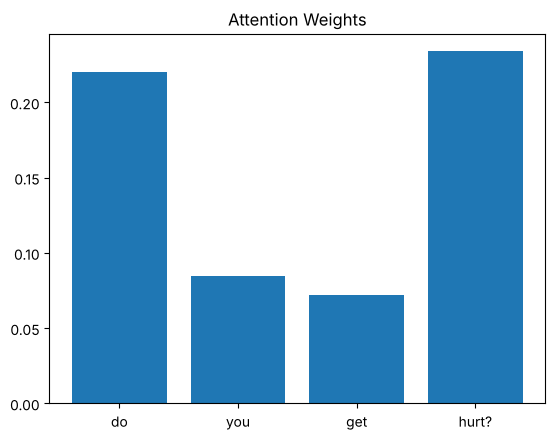

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

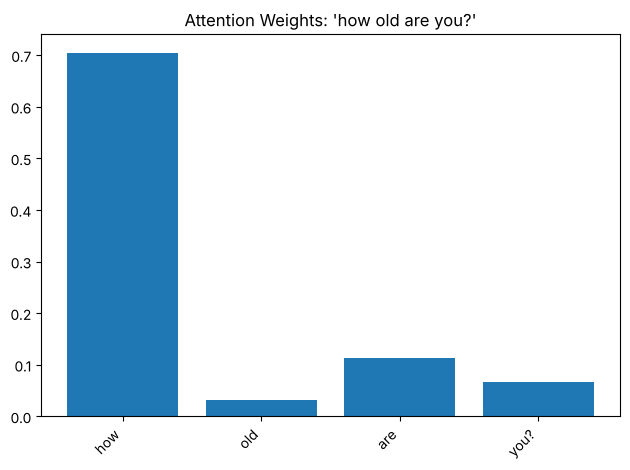

Question: 'how old are you?'
Highest-attention word: 'how' (weight=0.7047)



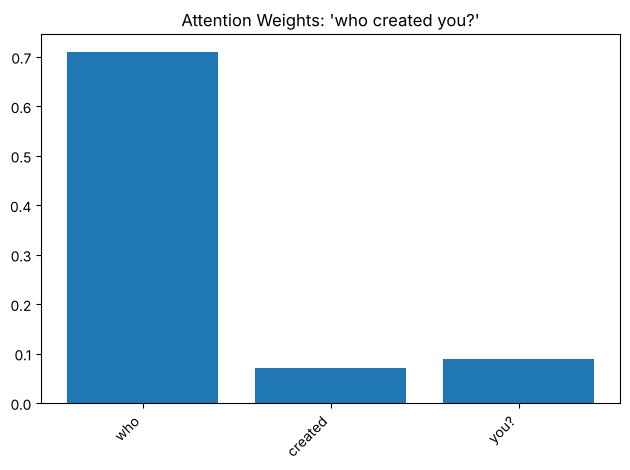

Question: 'who created you?'
Highest-attention word: 'who' (weight=0.7097)



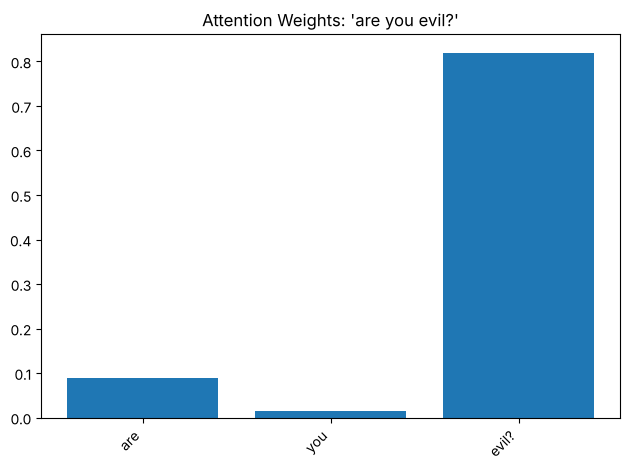

Question: 'are you evil?'
Highest-attention word: 'evil?' (weight=0.8196)



In [7]:
def show_attention(row_idx, title=None):
    question_text = df["question"][row_idx]
    words = question_text.split()

    with torch.no_grad():
        prediction, weights = model(X[row_idx:row_idx + 1])

    w = weights[0, :len(words)].tolist()

    plt.figure()
    plt.bar(words, w)
    plt.title(title or f"Attention Weights: {question_text!r}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    top_idx = w.index(max(w))
    top_word = words[top_idx]
    print(f"Question: {question_text!r}")
    print(f"Highest-attention word: {top_word!r} (weight={w[top_idx]:.4f})\n")
    return top_word, w


# Three different questions from the dataset
task1_questions = ["how old are you?", "who created you?", "are you evil?"]
task1_indices = [df.index[df["question"] == q][0] for q in task1_questions]

for idx in task1_indices:
    show_attention(idx)


**Reflection:** the highest-attention word varies across these three questions, and it is not
always the word that intuitively carries the most meaning. For *"how old are you?"* the model
attends most to *"how"* (0.70), and for *"who created you?"* it attends most to *"who"* (0.71) --
in both cases a question word, rather than the more semantically loaded word ("old", "created").
For *"are you evil?"*, however, attention concentrates on *"evil?"* itself (0.82), the one word
that actually determines the answer. So the pattern is mixed: the model has clearly learned that
the leading question word is a strong, easy-to-use signal for distinguishing some question
classes (since many "who ..." and "how ..." questions map to different answer groups), while for
others the distinguishing content word dominates instead. This makes sense for a model trained on
a small, templated dataset -- it is free to latch onto whatever single token is most predictive,
and that is not necessarily the word a human would consider most "important."

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question A:


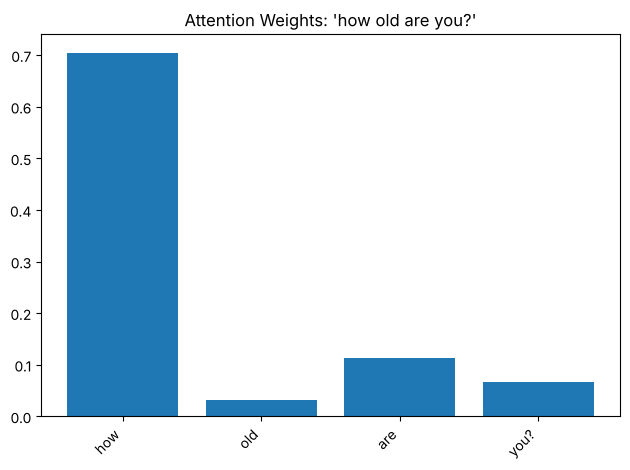

Question: 'how old are you?'
Highest-attention word: 'how' (weight=0.7047)

Question B:


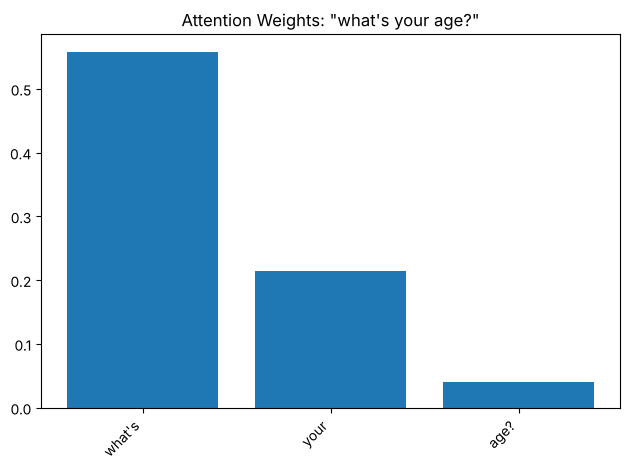

Question: "what's your age?"
Highest-attention word: "what's" (weight=0.5573)

Top word for Question A ('how old are you?'): 'how'
Top word for Question B ("what's your age?"): "what's"


In [8]:
# Two questions with similar meaning (both asking about age) but different wording
q_a = "how old are you?"
q_b = "what's your age?"

idx_a = df.index[df["question"] == q_a][0]
idx_b = df.index[df["question"] == q_b][0]

print("Question A:")
top_word_a, weights_a = show_attention(idx_a, title=f"Attention Weights: {q_a!r}")

print("Question B:")
top_word_b, weights_b = show_attention(idx_b, title=f"Attention Weights: {q_b!r}")

print(f"Top word for Question A ({q_a!r}): {top_word_a!r}")
print(f"Top word for Question B ({q_b!r}): {top_word_b!r}")


**Reflection:** the model focuses on different words for these two same-meaning questions --
*"how"* for *"how old are you?"* (0.70) and *"what's"* for *"what's your age?"* (0.56). Neither
question's top word is the shared content word ("old"/"age") that actually conveys the shared
meaning; instead, in both cases the model leans on the leading question word. This suggests the
attention mechanism here hasn't learned a paraphrase-invariant notion of "what the question is
about" -- it's learned which literal tokens were most predictive of the correct answer class
during training on this specific small dataset, and different phrasings offer different
easy-to-use cues (even if those cues happen to be question words rather than the real topic
word). With a larger, more varied training set covering many phrasings of the same underlying
question, we'd expect attention to rely less on superficial sentence openers and more on the
genuinely informative content words, regardless of exact wording.